### Import

In [2]:
import numpy as np
import pandas as pd
from glob import glob
import matplotlib.pyplot as plt
import cv2
import os
from pathlib import Path

### Path

In [ ]:
#Insert path to dataset
path = ""

metadata = pd.read_json( path + 'Fundus_CIMT_2903_Dataset/data_info.json')
retina_images = glob(path + 'Fundus_CIMT_2903_Dataset/images/*.png')

## Remove text overaly

### Testing removal

Testing overlay removal on sample images...

100464002_L.png: No overlay detected
100464002_R.png: No overlay detected
100468003_L.png: No overlay detected


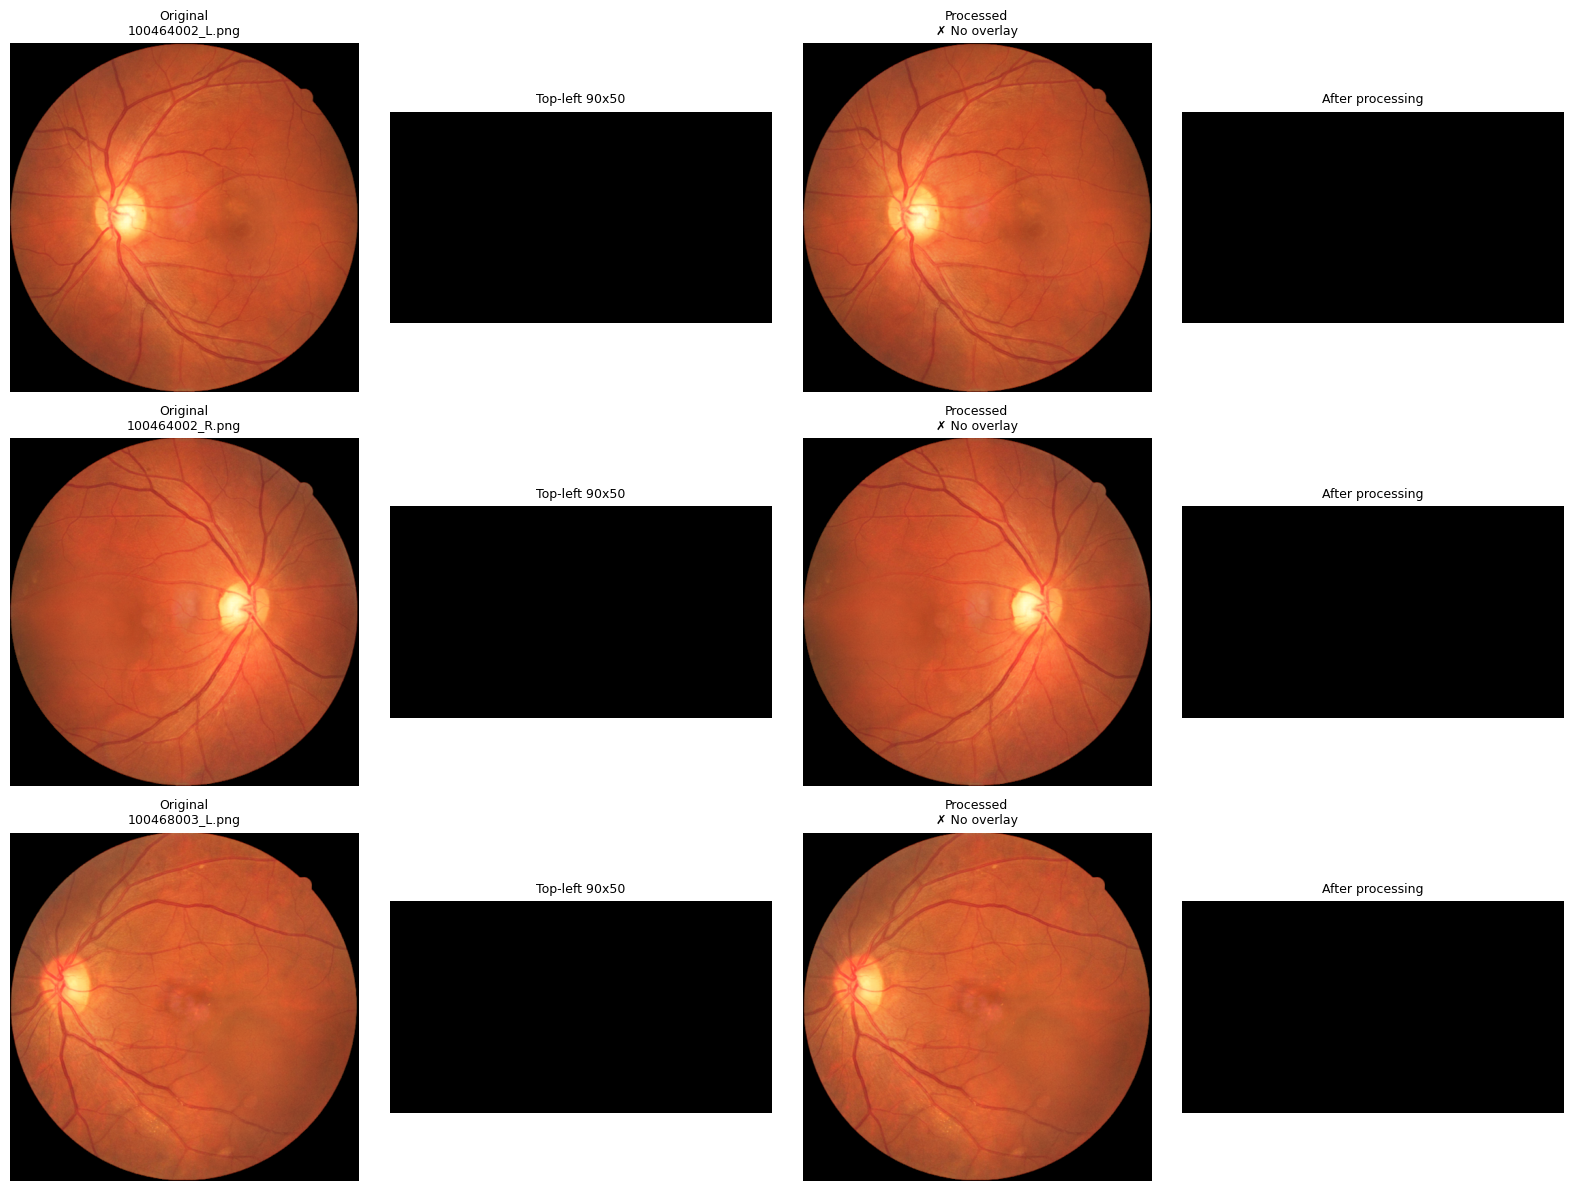

In [4]:
def remove_top_left_overlay(img, width=90, height=50, white_threshold=200, white_ratio=0.25):
    """
    Black out top-left corner if it has >25% white pixels.
    
    Args:
        img: Image array (RGB or BGR)
        width: Width of area to check (default 90)
        height: Height of area to check (default 50)
        white_threshold: Pixel value considered white (default 200)
        white_ratio: Ratio of white pixels to trigger blackout (default 0.25 = 25%)
    
    Returns:
        Modified image with top-left blacked out if needed
    """
    img_copy = img.copy()
    
    # Get top-left region
    top_left = img_copy[:height, :width]
    
    # Convert to grayscale to check intensity
    if len(top_left.shape) == 3:
        gray = cv2.cvtColor(top_left, cv2.COLOR_RGB2GRAY)
    else:
        gray = top_left
    
    # Count white pixels
    white_pixels = np.sum(gray > white_threshold)
    total_pixels = gray.size
    ratio = white_pixels / total_pixels
    
    # Black out if there's any white pixel
    if white_pixels > 0:
        img_copy[:height, :width] = 0
        return img_copy, True
    
    return img_copy, False


# Test on a few images
print("Testing overlay removal on sample images...\n")

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for i in range(3):
    if i < len(retina_images):
        img_path = retina_images[i]
        img = plt.imread(img_path)
        
        # Original
        axes[i, 0].imshow(img)
        axes[i, 0].set_title(f"Original\n{Path(img_path).name}", fontsize=9)
        axes[i, 0].axis('off')
        
        # Top-left zoom
        axes[i, 1].imshow(img[:50, :90])
        axes[i, 1].set_title("Top-left 90x50", fontsize=9)
        axes[i, 1].axis('off')
        
        # Processed
        processed, had_overlay = remove_top_left_overlay(img)
        axes[i, 2].imshow(processed)
        axes[i, 2].set_title(f"Processed\n{'✓ Removed' if had_overlay else '✗ No overlay'}", fontsize=9)
        axes[i, 2].axis('off')
        
        # Processed top-left zoom
        axes[i, 3].imshow(processed[:50, :90])
        axes[i, 3].set_title("After processing", fontsize=9)
        axes[i, 3].axis('off')
        
        print(f"{Path(img_path).name}: {'Overlay removed' if had_overlay else 'No overlay detected'}")

plt.tight_layout()
plt.show()

### Remove all text overlays and save

In [5]:
# Process all images and save them
output_dir = path + "Fundus_CIMT_2903_Dataset/images_no_overlay/"
os.makedirs(output_dir, exist_ok=True)

print(f"Processing {len(retina_images)} images...\n")

overlay_count = 0
for i, img_path in enumerate(retina_images):
    img = cv2.imread(img_path)
    if img is None:
        print(f"Failed to read: {img_path}")
        continue
    
    # Convert BGR to RGB
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # Remove overlay
    processed, had_overlay = remove_top_left_overlay(img_rgb)
    
    if had_overlay:
        overlay_count += 1
    
    # Convert back to BGR for saving
    processed_bgr = cv2.cvtColor(processed, cv2.COLOR_RGB2BGR)
    
    # Save
    output_path = os.path.join(output_dir, Path(img_path).name)
    cv2.imwrite(output_path, processed_bgr)
    
    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(retina_images)} images...")

print(f"\nDone!")
print(f"Images with overlay removed: {overlay_count}/{len(retina_images)}")
print(f"Saved to: {output_dir}")

Processing 5806 images...

Processed 100/5806 images...
Processed 200/5806 images...
Processed 300/5806 images...
Processed 400/5806 images...
Processed 500/5806 images...
Processed 600/5806 images...
Processed 700/5806 images...
Processed 800/5806 images...
Processed 900/5806 images...
Processed 1000/5806 images...
Processed 1100/5806 images...
Processed 1200/5806 images...
Processed 1300/5806 images...
Processed 1400/5806 images...
Processed 1500/5806 images...
Processed 1600/5806 images...
Processed 1700/5806 images...
Processed 1800/5806 images...
Processed 1900/5806 images...
Processed 2000/5806 images...
Processed 2100/5806 images...
Processed 2200/5806 images...
Processed 2300/5806 images...
Processed 2400/5806 images...
Processed 2500/5806 images...
Processed 2600/5806 images...
Processed 2700/5806 images...
Processed 2800/5806 images...
Processed 2900/5806 images...
Processed 3000/5806 images...
Processed 3100/5806 images...
Processed 3200/5806 images...
Processed 3300/5806 im